# Preliminary analysis of trends

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
import statsmodels.api as sm
from statsmodels.tsa.stattools import acf, pacf, adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

warnings.filterwarnings("ignore")   # kpss/adfuller spam InterpolationWarnings
plt.rcParams["figure.figsize"] = (11, 4)

In [2]:
df = pd.read_csv("prices.txt", sep=r"\s+", header=0)
tickers = df.columns.to_numpy()
prc = df.values.T                       # (nInst, nt) — eval's orientation, ALGO = row 0
nInst, nt = prc.shape
rets = np.diff(np.log(prc), axis=1)     # rets[:, t] = close t → close t+1

ret_df = pd.DataFrame(rets.T, columns=tickers)   # days-as-rows view, nicer for plotting/.rolling

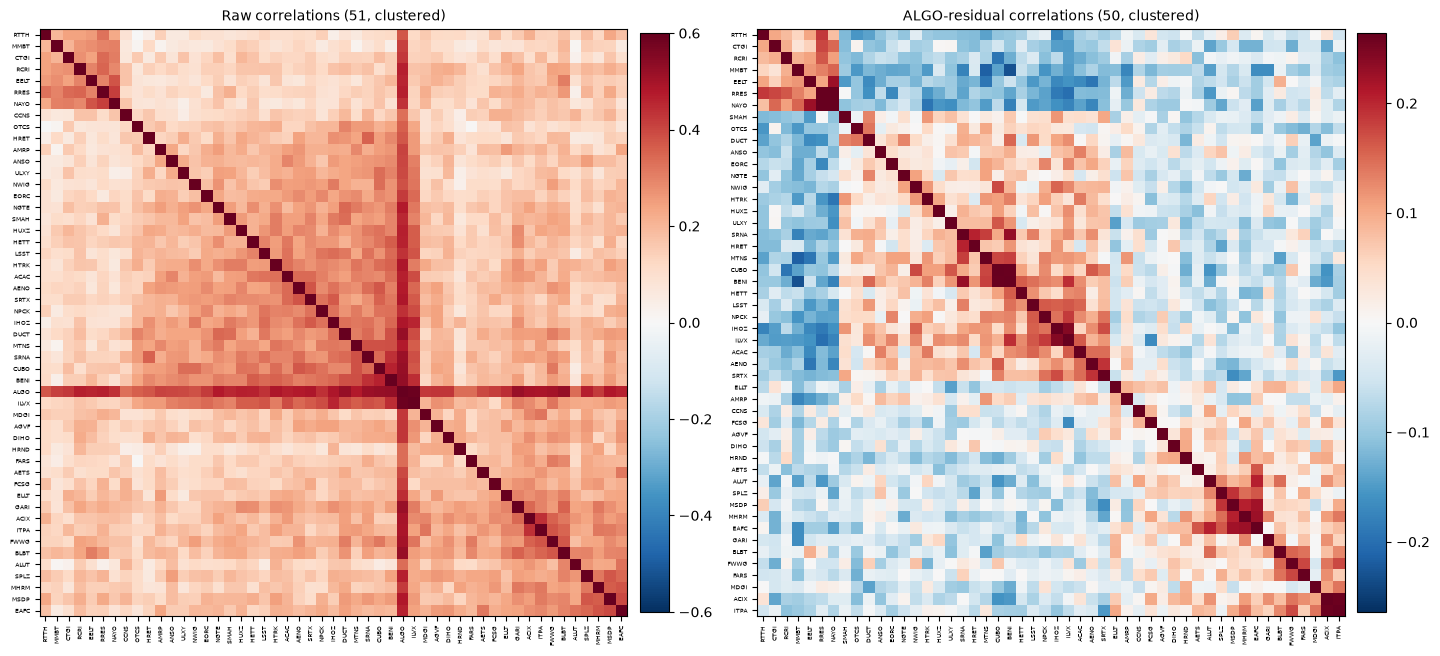

mean off-diag: raw 0.200 | residual -0.010
null benchmark for max |rho| over 1225 pairs at T=499: ~0.17
 RRES - NAYO  resid rho = +0.264
 CUBO - BENI  resid rho = +0.260
 ACIX - ITPA  resid rho = +0.259
 IHOZ - ILVX  resid rho = +0.242
 MMBT - BENI  resid rho = -0.230
 SRNA - BENI  resid rho = +0.229
 NAYO - EELT  resid rho = +0.227
 MHRM - EAFC  resid rho = +0.225
 MSDP - EAFC  resid rho = +0.222
 MMBT - MTNS  resid rho = -0.216


In [3]:
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform

# --- correlation matrices ----------------------------------------------
C_raw = np.corrcoef(rets)                        # all 51, incl. ALGO

X = rets - rets.mean(axis=1, keepdims=True)
a = X[0]                                         # ALGO = the factor
beta = X @ a / (a @ a)                           # per-instrument loading
resid = X - np.outer(beta, a)                    # factor-neutral returns
C_res = np.corrcoef(resid[1:])                   # 50x50, ALGO dropped

iu  = np.triu_indices_from(C_res, k=1)
off = C_res[iu]

def cluster_order(C):
    Z = linkage(squareform(1.0 - C, checks=False), method="average")
    return leaves_list(Z)

o1, o2 = cluster_order(C_raw), cluster_order(C_res)

# --- plot ---------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14.5, 6.8))
panels = [
    (C_raw[np.ix_(o1, o1)], tickers[o1],     "Raw correlations (51, clustered)",           0.6),
    (C_res[np.ix_(o2, o2)], tickers[1:][o2], "ALGO-residual correlations (50, clustered)", max(0.2, np.abs(off).max())),
]
for ax, (M, names, title, vlim) in zip(axes, panels):
    im = ax.imshow(M, cmap="RdBu_r", vmin=-vlim, vmax=vlim, interpolation="nearest")
    ax.set_title(title, fontsize=10)
    ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=90, fontsize=4.5)
    ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=4.5)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)
plt.tight_layout(); plt.show()

# --- numbers to go with the picture -------------------------------------
T = rets.shape[1]
print(f"mean off-diag: raw {C_raw[np.triu_indices_from(C_raw, 1)].mean():.3f} | residual {off.mean():.3f}")
print(f"null benchmark for max |rho| over {off.size} pairs at T={T}: ~{np.sqrt(2*np.log(off.size)/T):.2f}")
for k in np.argsort(-np.abs(off))[:10]:
    i, j = iu[0][k], iu[1][k]
    print(f"{tickers[1:][i]:>5} - {tickers[1:][j]:<5} resid rho = {off[k]:+.3f}")